In [18]:
import pandas as pd

In [19]:
data = pd.read_csv("C:/Users/saura/Downloads/Heart.csv")
data.head()


,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   Age         303 non-null    int64  
 2   Sex         303 non-null    int64  
 3   ChestPain   303 non-null    object 
 4   RestBP      303 non-null    int64  
 5   Chol        303 non-null    int64  
 6   Fbs         303 non-null    int64  
 7   RestECG     303 non-null    int64  
 8   MaxHR       303 non-null    int64  
 9   ExAng       303 non-null    int64  
 10  Oldpeak     303 non-null    float64
 11  Slope       303 non-null    int64  
 12  Ca          299 non-null    float64
 13  Thal        301 non-null    object 
 14  AHD         303 non-null    object 
dtypes: float64(2), int64(10), object(3)
memory usage: 35.6+ KB


In [21]:
data.dropna(inplace = True)     # Remove all rows that contain missing values from the dataset.

In [22]:
import matplotlib.pyplot as plt    # create graphs such as line charts, bar charts, and histograms.
import seaborn as sns              # create statistical visualizations such as heatmaps, box plots, and count plots.

In [23]:
def chkOutliers (data, column):
    plt.figure(figsize = (7, 3))
    plt.subplot(1, 2, 1)   # row size, column size, plot no)
    plt.boxplot(data[column])
    plt.subplot(1, 2, 2)
    m = data[column].mean()
    std = data[column].std()
    sns.histplot(data[column], kde = True)
    plt.axvline(m, color = "green")
    plt.axvline(m - 3 * std, color = "red")
    plt.axvline(m + 3 * std, color = "red")
    plt.show

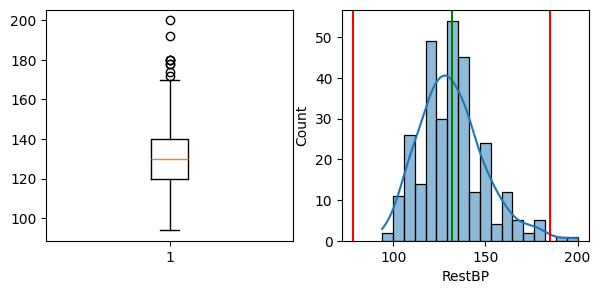

In [24]:
chkOutliers(data, "RestBP")

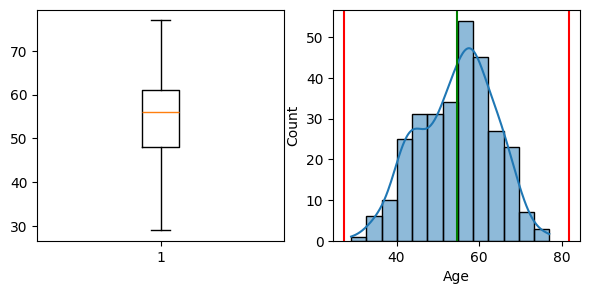

In [25]:
chkOutliers(data, "Age")

In [31]:
def replaceOutliers(data, column):
    q3 =  data[column].quantile(0.75)
    q1 = data[column].quantile(0.25)
    iqr = q3 - q1
    ub = q3 + iqr * 1.5
    lb = q1 - iqr * 1.5
    data.loc[data[column] > ub, column] = ub
    data.loc[data[column] < lb, column] = lb

In [32]:
replaceOutliers(data, "RestBP")

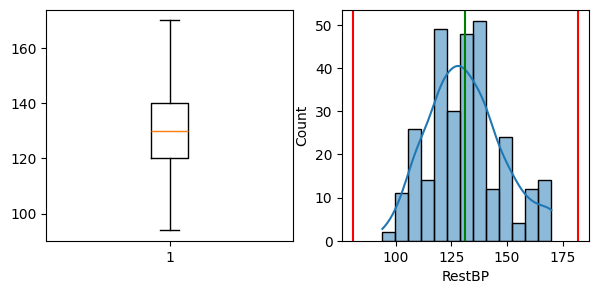

In [33]:
chkOutliers(data, "RestBP")

In [34]:
data["ChestPain"].unique()

array([0, 1, 2, 3])

In [30]:
data = data.replace({'typical' : 0, 'asymptomatic' : 1, 'nonanginal' : 2, 'nontypical' : 3})

C:\Users\saura\AppData\Local\Temp\ipykernel_23080\528187286.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = data.replace({'typical' : 0, 'asymptomatic' : 1, 'nonanginal' : 2, 'nontypical' : 3})


In [35]:
data.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,0,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,1,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,1,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,2,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,3,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [36]:
data["Thal"].unique()

array(['fixed', 'normal', 'reversable'], dtype=object)

In [37]:
data = data.replace({'fixed' : 0, 'normal' : 1, 'reversable' : 2})

C:\Users\saura\AppData\Local\Temp\ipykernel_23080\4143091216.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = data.replace({'fixed' : 0, 'normal' : 1, 'reversable' : 2})


In [38]:
data.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,0,145,233,1,2,150,0,2.3,3,0.0,0,No
1,2,67,1,1,160,286,0,2,108,1,1.5,2,3.0,1,Yes
2,3,67,1,1,120,229,0,2,129,1,2.6,2,2.0,2,Yes
3,4,37,1,2,130,250,0,0,187,0,3.5,3,0.0,1,No
4,5,41,0,3,130,204,0,2,172,0,1.4,1,0.0,1,No


In [40]:
X = data.drop(["Unnamed: 0", "AHD"], axis = 1)
y = data["AHD"]

In [41]:
from sklearn.model_selection import train_test_split

In [42]:
X_train, X_test, y_train, y_test = train_test_split (X, y, random_state=4, test_size=0.3)

In [43]:
from sklearn.ensemble import RandomForestClassifier

In [44]:
model = RandomForestClassifier()
model.fit(X_train, y_train)

RandomForestClassifier()

In [45]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

In [47]:
from sklearn.metrics import accuracy_score
print("Training accuracy:" , accuracy_score(y_train, train_pred))
print("Testing accuracy:" , accuracy_score(y_test, test_pred))

Training accuracy: 1.0
Testing accuracy: 0.8333333333333334


In [49]:
# evaluate its performance
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred))

[[38  4]
 [11 37]]
              precision    recall  f1-score   support

          No       0.78      0.90      0.84        42
         Yes       0.90      0.77      0.83        48

    accuracy                           0.83        90
   macro avg       0.84      0.84      0.83        90
weighted avg       0.84      0.83      0.83        90



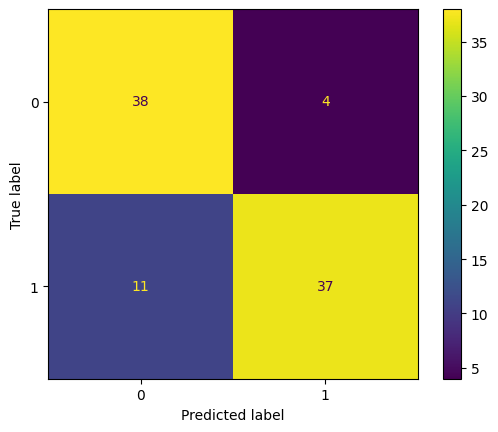

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.show()

In [51]:
print("Training accuracy:", accuracy_score(y_train, train_pred))
print("Testing accuracy:", accuracy_score(y_test, test_pred))

Training accuracy: 1.0
Testing accuracy: 0.8333333333333334


In [52]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

ROC-AUC Score: 0.8965773809523809


C:\Users\saura\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


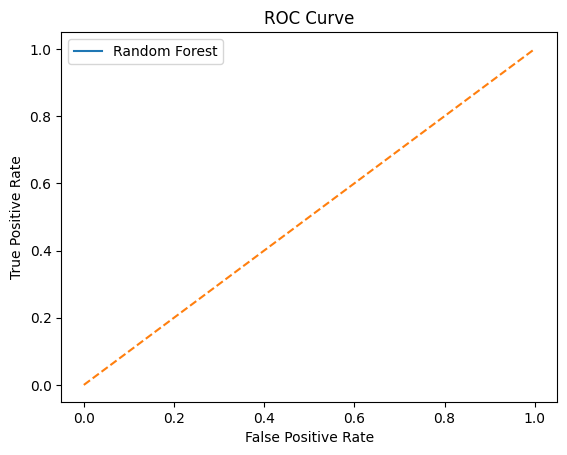

In [53]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=1)

plt.plot(fpr, tpr, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [54]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance)

      Feature  Importance
7       MaxHR    0.146326
11         Ca    0.140964
12       Thal    0.106557
9     Oldpeak    0.095817
0         Age    0.093178
4        Chol    0.084595
2   ChestPain    0.083717
3      RestBP    0.079956
8       ExAng    0.073925
1         Sex    0.035074
10      Slope    0.028618
6     RestECG    0.019796
5         Fbs    0.011477


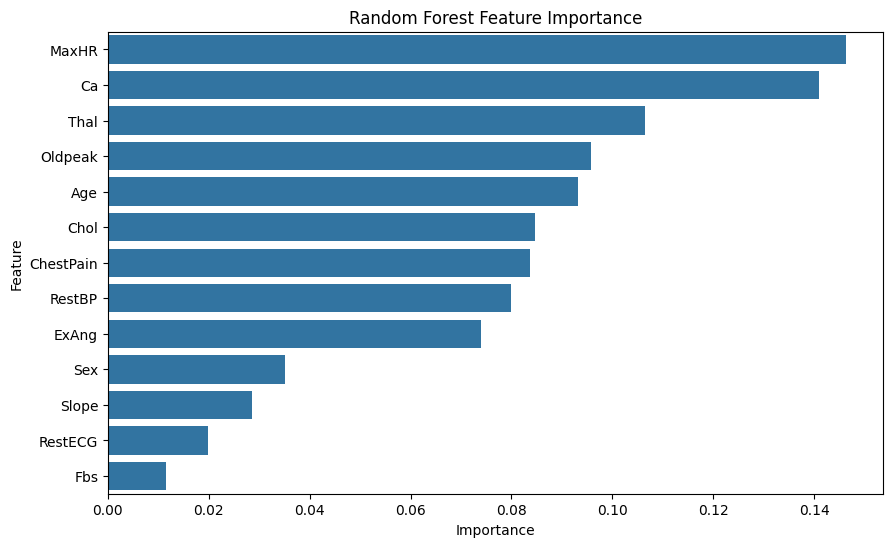

In [55]:
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.show()

In [56]:
import joblib

joblib.dump(model, "heart_disease_model.pkl")

['heart_disease_model.pkl']

In [58]:
loaded_model = joblib.load("heart_disease_model.pkl")

prediction = loaded_model.predict(X_test.iloc[[0]])
print("Predicted result:", prediction)

Predicted result: ['Yes']


In [59]:
print("Predicted:", loaded_model.predict(X_test.iloc[[0]])[0])
print("Actual:", y_test.iloc[0])

Predicted: Yes
Actual: Yes


In [60]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_pred
})

print(results.head(10))

    Actual Predicted
248    Yes       Yes
61      No        No
69     Yes        No
24     Yes       Yes
117     No        No
245    Yes        No
158    Yes       Yes
13      No        No
164     No        No
107    Yes       Yes


In [61]:
print(results["Actual"].eq(results["Predicted"]).value_counts())

True     75
False    15
Name: count, dtype: int64


In [62]:
results.to_csv("heart_disease_predictions.csv", index=False)

In [63]:
print("Model: Random Forest Classifier")
print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy:", accuracy_score(y_test, test_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

Model: Random Forest Classifier
Training Accuracy: 1.0
Testing Accuracy: 0.8333333333333334
ROC-AUC Score: 0.8965773809523809


In [64]:
patient = X.iloc[[0]].copy()

patient.loc[patient.index[0], "Age"] = 55

prediction = model.predict(patient)
print("Heart Disease Prediction:", prediction[0])

Heart Disease Prediction: No


In [65]:
patient = X.iloc[[1]].copy()

patient.loc[patient.index[0], "Age"] = 45
patient.loc[patient.index[0], "RestBP"] = 130

prediction = model.predict(patient)
print("Heart Disease Prediction:", prediction[0])

Heart Disease Prediction: Yes


In [66]:
if prediction[0] == "Yes":
    print("Model predicts: Heart disease detected")
else:
    print("Model predicts: No heart disease detected")

Model predicts: Heart disease detected
